# Customer Churn Prediction — Complete Industry-Style ML Project

**Purpose:** learn how to take a supervised ML problem from a business question to a tested, evaluated, deployable, monitorable model—and be able to explain the decisions in an interview.

This is a **portfolio project using public data**, not a claim that this system was deployed at an employer.

## How to use this notebook

- Run cells from top to bottom in order.
- Read the explanation **before** running each code cell.
- When a cell produces a surprising result, stop and explain it in your own words before continuing.
- Do not copy a metric into your resume until you have run the notebook and recorded the actual result from your run.
- This notebook teaches the reasoning. A real repository should split reusable logic into modules, tests, API code, configuration, and CI workflows.

### Project lifecycle

1. Define the business problem and success criteria.
2. Load data; validate schema, quality, provenance, and leakage risks.
3. Explore data and build reproducible preprocessing.
4. Establish a simple baseline and compare candidate models.
5. Validate the model, analyze errors, and choose a decision threshold.
6. Track experiments and manage model artifacts.
7. Add data, transformation, and prediction tests.
8. Prepare a serving interface and deployment packaging.
9. Monitor service health, data drift, and delayed model quality.
10. Define retraining, release, rollback, and incident procedures.
11. Consider latency, cost, privacy, security, and responsible use.
12. Document decisions and prepare interview answers.

**Important:** the order is a useful workflow, not a law. For example, data quality and leakage checks continue throughout a project.

# Project map — the agreed 12-step framework

This notebook is organized around **exactly 12 main steps**. The headings inside each step are **subsections**, not additional framework steps. Some subsections are practical experiments; others are implementation templates or production-design guidance.

1. 1. Business problem and requirements
2. 2. Data collection, quality, and lineage
3. 3. EDA and feature engineering/preprocessing
4. 4. Baseline and model development
5. 5. Evaluation and error analysis
6. 6. Reproducibility and model management
7. 7. ML-specific testing and quality gates
8. 8. Deployment and serving
9. 9. Production monitoring
10. 10. Operations and continuous improvement
11. 11. Performance, cost, and security
12. 12. Documentation and interview readiness

## How to read the hierarchy

- **STEP 1–12** are the only main framework steps.
- `Subsection 1.1`, `1.2`, etc. are learning topics inside each step.
- A topic described as a template/design exercise is not automatically a deployed production feature.


### STEP 1 — Business problem and requirements

#### 1.1 Environment and reproducibility

A notebook is an experiment, so record the software environment and random seeds. Reproducibility means we can understand and repeat a run; it does **not** guarantee bit-for-bit identical results across all hardware, library versions, or parallel execution settings.

Install the dependencies in your terminal if needed:

```bash
python -m pip install pandas numpy matplotlib seaborn scikit-learn joblib requests
```

Optional sections later use `mlflow`, `fastapi`, `uvicorn`, `prometheus-client`, and `evidently` only if you choose to install them. This notebook keeps the core workflow runnable without those optional packages.

In [1]:
from __future__ import annotations

import json
import os
import platform
import sys
import time
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
import seaborn as sns

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, average_precision_score, brier_score_loss,
    classification_report, confusion_matrix, f1_score,
    precision_recall_curve, precision_score, recall_score,
    roc_auc_score, RocCurveDisplay, PrecisionRecallDisplay
)
from sklearn.model_selection import (
    StratifiedKFold, cross_validate, train_test_split
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# NumPy 2.x on Apple Silicon (Accelerate BLAS) emits spurious
# "divide by zero / overflow / invalid value encountered in matmul" warnings
# even on clean, finite data. Results are correct, so silence only these.
warnings.filterwarnings("ignore", message=r".*encountered in matmul", category=RuntimeWarning)

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

print("Python:", sys.version.split()[0])
print("Platform:", platform.platform())
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("Run started (UTC):", datetime.now(timezone.utc).isoformat())

Python: 3.10.20
Platform: macOS-26.7.1-arm64-arm-64bit
pandas: 2.3.3
scikit-learn: 1.7.2
Run started (UTC): 2026-10-14T10:02:11.406822+00:00


#### 1.2 Business problem and success criteria

### Business question

A subscription business wants to identify customers who are at risk of cancelling so its retention team can decide whom to contact.

A classifier does not directly create business value. The **decision made from its predictions** creates value. For example, a high-risk score may trigger a retention offer, but offers cost money and some customers would have stayed anyway.

### Define the problem before training

- **Prediction unit:** one customer at a defined scoring time.
- **Target:** whether the customer churned in the dataset's observation window.
- **Prediction type:** binary classification and, ideally, a calibrated risk score.
- **Potential action:** prioritize customers for a retention intervention.
- **Business constraints:** outreach capacity, offer cost, customer experience, privacy, and intervention effectiveness.
- **Baseline:** a simple rule or majority-class predictor, followed by a business-relevant model.
- **Primary offline metrics:** average precision / PR-AUC and recall/precision at an operational threshold. ROC-AUC is a secondary ranking metric.
- **Business metric:** incremental retained customers or profit from a controlled experiment—not merely accuracy.

### Interview point

**Question:** Why not optimize accuracy?

If only a small fraction of customers churn, predicting “no churn” for everyone can achieve high accuracy while finding no churners. We need metrics that reflect class imbalance and the cost of different errors.

### STEP 2 — Data collection, quality, and lineage

#### 2.1 Data source, provenance, and data contract

We use the public IBM Telco Customer Churn dataset as an educational example. It is not production customer data.

The CSV is downloaded from a public GitHub mirror. Public mirrors can move or disappear; for a repeatable team project, pin a known dataset version, preserve its license/source details, and record a checksum.

**Data contract (expected schema):**
- `customerID`: identifier; useful for joins, generally not a predictive feature.
- `Churn`: target label (`Yes` / `No`).
- Other columns: customer account, service, and billing attributes.

**Leakage question:** Would every feature be known at the exact moment we want to score a customer? If a feature is recorded after churn, cancellation, or a retention intervention, it can leak the answer. This dataset is a teaching dataset and does not provide a fully specified production prediction timestamp, so real deployment would require a time-aware data audit.

In [2]:
DATA_URL = (
    # Official IBM repository (the earlier blastchar mirror now returns 404).
    "https://raw.githubusercontent.com/"
    "IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"
)
DATA_DIR = Path("data/raw")
DATA_DIR.mkdir(parents=True, exist_ok=True)
DATA_PATH = DATA_DIR / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

if DATA_PATH.exists():
    df_raw = pd.read_csv(DATA_PATH)
    print(f"Loaded cached dataset: {DATA_PATH}")
else:
    try:
        df_raw = pd.read_csv(DATA_URL)
        df_raw.to_csv(DATA_PATH, index=False)
        print(f"Downloaded and cached dataset: {DATA_PATH}")
    except Exception as exc:
        raise RuntimeError(
            "Could not download the public dataset. Check your internet connection "
            "or download the CSV manually and place it at DATA_PATH."
        ) from exc

print("Shape:", df_raw.shape)
display(df_raw.head())

Loaded cached dataset: data/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Shape: (7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


#### 2.2 Schema and data-quality checks

Do not start modeling just because `read_csv` worked. Validate the data you actually received.

Checks in this section:
- required columns exist;
- duplicate records and duplicate customer IDs;
- missing values and data types;
- target values and target distribution;
- invalid values in a numeric-looking column;
- a basic data profile to save with the run.

A **data contract** is an explicit agreement about expected columns, types, allowed values, nullability, and sometimes ranges. Schema validation should fail loudly when the input changes unexpectedly.

In [3]:
REQUIRED_COLUMNS = {
    "customerID", "Churn", "tenure", "MonthlyCharges", "TotalCharges",
    "Contract", "InternetService", "PaymentMethod"
}
missing_columns = REQUIRED_COLUMNS - set(df_raw.columns)
assert not missing_columns, f"Missing required columns: {sorted(missing_columns)}"
assert len(df_raw) > 0, "Dataset is empty"

print("Duplicate full rows:", int(df_raw.duplicated().sum()))
print("Duplicate customer IDs:", int(df_raw["customerID"].duplicated().sum()))
print("\nColumn dtypes:")
display(df_raw.dtypes.to_frame("dtype"))
print("\nMissing values:")
display(df_raw.isna().sum().sort_values(ascending=False).to_frame("missing_count"))
print("\nTarget values:")
display(df_raw["Churn"].value_counts(dropna=False).to_frame("count"))

Duplicate full rows: 0
Duplicate customer IDs: 0

Column dtypes:


,dtype
customerID,object
gender,object
SeniorCitizen,int64
Partner,object
Dependents,object
tenure,int64
PhoneService,object
MultipleLines,object
InternetService,object
OnlineSecurity,object



Missing values:


,missing_count
customerID,0
DeviceProtection,0
TotalCharges,0
MonthlyCharges,0
PaymentMethod,0
PaperlessBilling,0
Contract,0
StreamingMovies,0
StreamingTV,0
TechSupport,0



Target values:


,count
Churn,
No,5174
Yes,1869


In [4]:
# `TotalCharges` is sometimes represented as text because blank strings occur.
df = df_raw.copy()
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

# Normalize the target only after inspecting the raw values.
target_values = set(df["Churn"].dropna().unique())
assert target_values <= {"Yes", "No"}, f"Unexpected target values: {target_values}"
assert df["Churn"].notna().all(), "Target contains missing labels"

df["Churn"] = df["Churn"].map({"No": 0, "Yes": 1}).astype("int8")

print("Rows:", len(df))
print("Target churn rate:", round(float(df["Churn"].mean()), 4))
print("TotalCharges missing after numeric conversion:", int(df["TotalCharges"].isna().sum()))
display(df.describe(include="all").T)

Rows: 7043
Target churn rate: 0.2654
TotalCharges missing after numeric conversion: 11


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customerID,7043,7043,7590-VHVEG,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,7043,2,Male,3555,NaN,NaN,NaN,NaN,NaN,NaN,NaN
SeniorCitizen,7043.0,NaN,NaN,NaN,0.162147,0.368612,0.0,0.0,0.0,0.0,1.0
Partner,7043,2,No,3641,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Dependents,7043,2,No,4933,NaN,NaN,NaN,NaN,NaN,NaN,NaN
tenure,7043.0,NaN,NaN,NaN,32.371149,24.559481,0.0,9.0,29.0,55.0,72.0
PhoneService,7043,2,Yes,6361,NaN,NaN,NaN,NaN,NaN,NaN,NaN
MultipleLines,7043,3,No,3390,NaN,NaN,NaN,NaN,NaN,NaN,NaN
InternetService,7043,3,Fiber optic,3096,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OnlineSecurity,7043,3,No,3498,NaN,NaN,NaN,NaN,NaN,NaN,NaN


#### 2.3 Data quality versus data cleaning

- **Data quality** asks whether the data is fit for the intended use.
- **Data cleaning** changes or repairs data to make it usable.
- **Data validation** checks whether data meets expected rules.
- **Data lineage** records where data came from and how it was transformed.

Do not blindly drop every row with a missing value. Understand why it is missing, whether missingness is informative, and whether dropping it changes the population. Here, we will impute numeric and categorical predictors inside the ML pipeline, so the imputation values are learned from training folds only.

### STEP 3 — EDA and feature engineering/preprocessing

#### 3.1 Exploratory data analysis (EDA)

EDA is used to understand the population, spot quality issues, formulate hypotheses, and choose sensible evaluation methods. It is **not** permission to select features by looking at the held-out test results.

We will inspect:
- target imbalance;
- numeric feature distributions;
- churn rates by a few business-relevant categories;
- numeric relationships.

Association is not causation. A category with high churn does not prove that category causes churn.

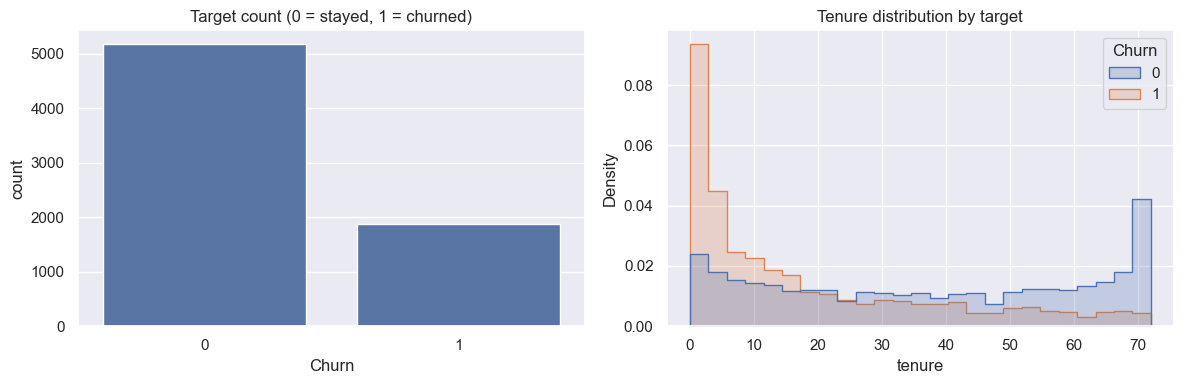

Class proportions:


,proportion
Churn,
0,0.73463
1,0.26537


In [5]:
sns.set_theme()
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x="Churn", ax=axes[0])
axes[0].set_title("Target count (0 = stayed, 1 = churned)")
axes[0].set_xlabel("Churn")
sns.histplot(data=df, x="tenure", hue="Churn", bins=25, stat="density",
             common_norm=False, element="step", ax=axes[1])
axes[1].set_title("Tenure distribution by target")
plt.tight_layout()
plt.show()

print("Class proportions:")
display(df["Churn"].value_counts(normalize=True).rename("proportion").to_frame())

In [6]:
for column in ["Contract", "InternetService", "PaymentMethod", "PaperlessBilling"]:
    if column in df.columns:
        rates = df.groupby(column, dropna=False)["Churn"].agg(["mean", "count"])
        rates = rates.sort_values("mean", ascending=False)
        print(f"Churn rate by {column}")
        display(rates.rename(columns={"mean": "churn_rate", "count": "customers"}))

Churn rate by Contract


,churn_rate,customers
Contract,,
Month-to-month,0.427097,3875
One year,0.112695,1473
Two year,0.028319,1695


Churn rate by InternetService


,churn_rate,customers
InternetService,,
Fiber optic,0.418928,3096
DSL,0.189591,2421
No,0.074050,1526


Churn rate by PaymentMethod


,churn_rate,customers
PaymentMethod,,
Electronic check,0.452854,2365
Mailed check,0.191067,1612
Bank transfer (automatic),0.167098,1544
Credit card (automatic),0.152431,1522


Churn rate by PaperlessBilling


,churn_rate,customers
PaperlessBilling,,
Yes,0.335651,4171
No,0.163301,2872


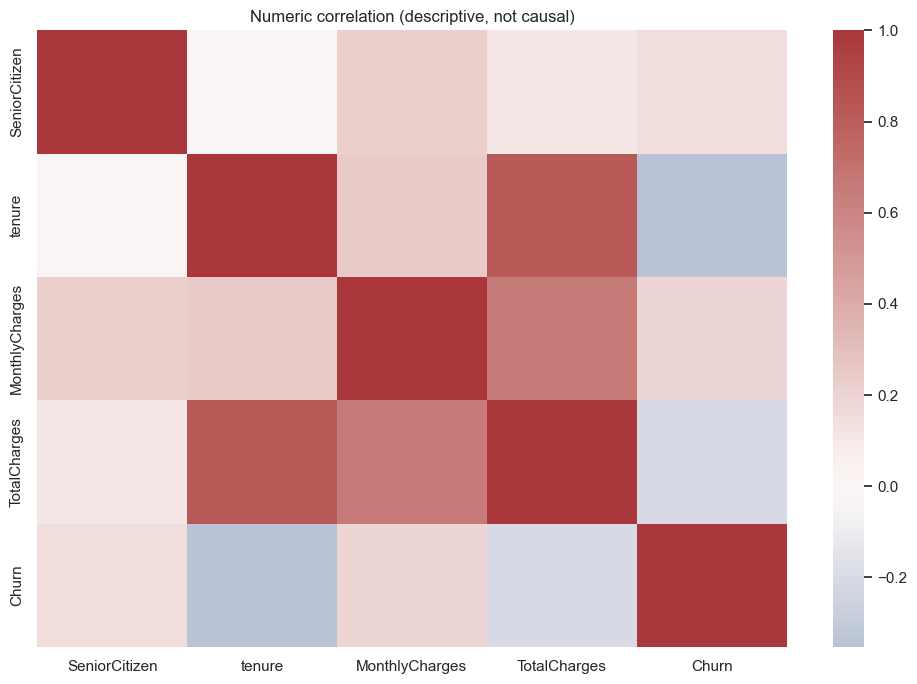

In [7]:
numeric_for_eda = df.select_dtypes(include=np.number).columns.tolist()
corr = df[numeric_for_eda].corr(numeric_only=True)
plt.figure(figsize=(10, 7))
sns.heatmap(corr, cmap="vlag", center=0, annot=False)
plt.title("Numeric correlation (descriptive, not causal)")
plt.tight_layout()
plt.show()

#### 3.2 EDA interview questions

1. Why do EDA before splitting and after splitting? General descriptive EDA on the full dataset can help understand it, but any data-driven decision that influences model fitting must avoid test leakage. For strict evaluation, conduct learned transformations and feature selection only on training data.
2. What is target leakage? A feature or transformation contains information unavailable at prediction time or information derived from the target.
3. What is survivorship / selection bias? The available dataset may omit customers who left earlier or customers who were never eligible for the sample.
4. Does correlation imply causation? No. Confounding, selection effects, and reverse causality can explain associations.

#### 3.3 Prediction target and leakage-aware splitting

We remove:
- `Churn`, because it is the label we are trying to predict;
- `customerID`, because it is an identifier and could encourage memorization without a defensible generalization signal.

A production feature set should be created using only information available at the scoring timestamp.

### Why three splits?

- **Training set:** fits candidate models and preprocessing.
- **Validation set:** selects the operating threshold and supports decisions that should not use the final test set.
- **Test set:** estimates final performance after choices are fixed.

The test set is not a tuning set. Repeatedly checking it and changing the system based on its results gradually overfits the test set.

We use stratified random splitting because this teaching dataset is not explicitly time-indexed for each customer's scoring event. For a real churn system, a temporal split is often more realistic: train on earlier periods, validate on a later period, and test on the latest period.

In [8]:
TARGET = "Churn"
ID_COLUMNS = ["customerID"]

X = df.drop(columns=[TARGET] + ID_COLUMNS)
y = df[TARGET].astype(int)

# First hold out 20% for the final test.
X_dev, X_test, y_dev, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

# Split the remaining 80% into training and validation.
# Validation is 20% of the development set, or 16% of the full dataset.
X_train, X_valid, y_train, y_valid = train_test_split(
    X_dev, y_dev, test_size=0.20, random_state=RANDOM_STATE, stratify=y_dev
)

split_summary = pd.DataFrame({
    "rows": [len(X_train), len(X_valid), len(X_test)],
    "churn_rate": [y_train.mean(), y_valid.mean(), y_test.mean()]
}, index=["train", "validation", "test"])
display(split_summary)

assert set(X_train.columns) == set(X_valid.columns) == set(X_test.columns)
assert X_train.index.intersection(X_valid.index).empty
assert X_train.index.intersection(X_test.index).empty
assert X_valid.index.intersection(X_test.index).empty

,rows,churn_rate
train,4507,0.265365
validation,1127,0.265306
test,1409,0.265436


#### 3.4 Preprocessing as part of the pipeline

### Why a pipeline?

Preprocessing must be learned from the training data and repeated identically during inference. If we impute or scale the entire dataset before cross-validation, information from validation folds leaks into the fitted transformation.

- Numeric columns: median imputation, then standardization.
- Categorical columns: most-frequent imputation, then one-hot encoding.
- Unknown categories at prediction time: `handle_unknown="ignore"` prevents the encoder from failing on a previously unseen category.
- All transformations are inside the model pipeline so cross-validation clones and fits them within each fold.

Scaling is important for Logistic Regression because feature magnitudes affect optimization and regularization. Tree-based models generally do not require scaling, but a shared preprocessing pipeline is convenient for this comparison.

We use dense one-hot output to make this notebook compatible with all candidate estimators below; for very high-cardinality data, dense matrices may consume too much memory. In that case use sparse-compatible estimators or a different encoding strategy.

In [9]:
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()

numeric_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

preprocessor = ColumnTransformer(transformers=[
    ("numeric", numeric_pipeline, numeric_features),
    ("categorical", categorical_pipeline, categorical_features)
], remainder="drop", verbose_feature_names_out=False)

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)
print("Raw feature count:", X_train.shape[1])

Numeric features: ['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']
Categorical features: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Raw feature count: 19


### STEP 4 — Baseline and model development

#### 4.1 Baseline before complex models

A baseline is a reference point. Without one, we cannot tell whether a complex model is useful.

The `DummyClassifier` below always predicts the most frequent class for its hard predictions. Its probability estimates are based on the class distribution. We will compare its ranking metric and accuracy with candidate models.

The baseline is not necessarily the business rule that a company currently uses. A production evaluation should compare against the existing policy or system too.

In [10]:
baseline = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", DummyClassifier(strategy="prior"))
])
baseline.fit(X_train, y_train)

baseline_proba = baseline.predict_proba(X_valid)[:, 1]
baseline_pred = (baseline_proba >= 0.5).astype(int)

baseline_results = {
    "accuracy_at_0.5": accuracy_score(y_valid, baseline_pred),
    "precision_at_0.5": precision_score(y_valid, baseline_pred, zero_division=0),
    "recall_at_0.5": recall_score(y_valid, baseline_pred, zero_division=0),
    "average_precision": average_precision_score(y_valid, baseline_proba),
    "roc_auc": roc_auc_score(y_valid, baseline_proba)
}
display(pd.Series(baseline_results, name="baseline").to_frame())

,baseline
accuracy_at_0.5,0.734694
precision_at_0.5,0.000000
recall_at_0.5,0.000000
average_precision,0.265306
roc_auc,0.500000


#### 4.2 Candidate models and cross-validation

We compare models with different inductive biases:
- **Logistic Regression:** linear decision boundary in transformed feature space; relatively interpretable and fast.
- **Random Forest:** bagged decision trees; models nonlinear interactions and reduces variance versus a single tree.
- **Extra Trees:** randomized split thresholds; often a strong tree ensemble baseline.
- **Histogram Gradient Boosting:** builds trees sequentially to correct previous errors; can capture complex patterns.

### Why stratified cross-validation?

A single split can be lucky or unlucky. Stratified K-fold tries to preserve class proportions in every fold. We use average precision as the main ranking metric because churn is imbalanced. Average precision summarizes the precision-recall curve; it is often called PR-AUC informally, though its exact calculation is not identical to every trapezoidal PR-area implementation.

The preprocessing is inside each pipeline, so each CV fold learns imputers, scaling, and encoding from that fold's training partition only.

In [11]:
candidate_models = {
    "LogisticRegression": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=300, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "HistGradientBoosting": HistGradientBoostingClassifier(
        max_iter=150, learning_rate=0.08, l2_regularization=1.0,
        random_state=RANDOM_STATE
    )
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {
    "average_precision": "average_precision",
    "roc_auc": "roc_auc",
    "precision": "precision",
    "recall": "recall",
    "f1": "f1"
}

cv_rows = []
fitted_candidates = {}

for name, estimator in candidate_models.items():
    candidate = Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator)
    ])
    cv_result = cross_validate(
        candidate, X_train, y_train, cv=cv, scoring=scoring,
        n_jobs=1, return_train_score=False
    )
    cv_rows.append({
        "model": name,
        "mean_average_precision": cv_result["test_average_precision"].mean(),
        "std_average_precision": cv_result["test_average_precision"].std(),
        "mean_roc_auc": cv_result["test_roc_auc"].mean(),
        "mean_precision_at_0.5": cv_result["test_precision"].mean(),
        "mean_recall_at_0.5": cv_result["test_recall"].mean(),
        "mean_f1_at_0.5": cv_result["test_f1"].mean()
    })

cv_results = pd.DataFrame(cv_rows).sort_values(
    "mean_average_precision", ascending=False
).reset_index(drop=True)
display(cv_results)

,model,mean_average_precision,std_average_precision,mean_roc_auc,mean_precision_at_0.5,mean_recall_at_0.5,mean_f1_at_0.5
0,LogisticRegression,0.656892,0.021768,0.843301,0.515377,0.801862,0.627437
1,RandomForest,0.641050,0.026079,0.835725,0.588260,0.633846,0.609299
2,HistGradientBoosting,0.633734,0.033925,0.828178,0.620132,0.510914,0.559697
3,ExtraTrees,0.614724,0.015773,0.825058,0.549838,0.678149,0.606796


#### 4.3 Model selection and trade-offs

The table ranks models by cross-validated average precision, but we should also consider:
- uncertainty across folds;
- calibration and threshold-specific performance;
- latency, memory, explainability, and operational complexity;
- performance across customer segments;
- whether the improvement is meaningful for the business.

For this educational workflow, we select the highest mean CV average precision, then fit it on the training set and use the validation set to choose an operating threshold. This is a transparent example—not a universal selection rule.

In [12]:
best_model_name = cv_results.loc[0, "model"]
best_estimator = candidate_models[best_model_name]

model = Pipeline(steps=[
    ("preprocessor", clone(preprocessor)),
    ("model", clone(best_estimator))
])
model.fit(X_train, y_train)

valid_proba = model.predict_proba(X_valid)[:, 1]
print("Selected model by mean CV average precision:", best_model_name)
print("Validation average precision:", round(average_precision_score(y_valid, valid_proba), 4))
print("Validation ROC-AUC:", round(roc_auc_score(y_valid, valid_proba), 4))

Selected model by mean CV average precision: LogisticRegression
Validation average precision: 0.6665
Validation ROC-AUC: 0.8483


### STEP 5 — Evaluation and error analysis

#### 5.1 Threshold selection using validation data and business costs

Most classifiers produce a probability or score. A **threshold** converts that score into an action:
- predict churn if score >= threshold;
- otherwise predict no churn.

The default 0.5 threshold is not automatically optimal. If missing a churner is expensive, a lower threshold may be justified, but that usually creates more false positives and more retention outreach.

For demonstration, we assign illustrative costs:
- false negative (missed churner): 5 units;
- false positive (unnecessary outreach): 1 unit.

These are **made-up teaching values**, not measured business economics. A real business should estimate intervention cost, churn probability, treatment effect, and expected customer value. The optimal action may require uplift modeling or experimentation—not just churn probability.

We select the threshold using validation data only. The final test set remains untouched until the decision is fixed.

In [13]:
FN_COST = 5.0  # illustrative cost of failing to identify a churner
FP_COST = 1.0  # illustrative cost of contacting a customer who would not churn

def threshold_cost(y_true, probabilities, threshold, fn_cost=FN_COST, fp_cost=FP_COST):
    y_true = np.asarray(y_true).astype(int)
    pred = (np.asarray(probabilities) >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    return {
        "threshold": float(threshold),
        "cost": float(fn_cost * fn + fp_cost * fp),
        "tn": int(tn), "fp": int(fp), "fn": int(fn), "tp": int(tp),
        "precision": float(precision_score(y_true, pred, zero_division=0)),
        "recall": float(recall_score(y_true, pred, zero_division=0)),
        "f1": float(f1_score(y_true, pred, zero_division=0))
    }

threshold_rows = [
    threshold_cost(y_valid, valid_proba, t)
    for t in np.linspace(0.05, 0.95, 91)
]
threshold_table = pd.DataFrame(threshold_rows)
best_threshold = float(
    threshold_table.loc[threshold_table["cost"].idxmin(), "threshold"]
)
print("Selected validation threshold:", round(best_threshold, 3))
display(threshold_table.sort_values("cost").head(10))

Selected validation threshold: 0.41


,threshold,cost,tn,fp,fn,tp,precision,recall,f1
36,0.41,490.0,538,290,40,259,0.471767,0.866221,0.610849
33,0.38,492.0,506,322,34,265,0.451448,0.886288,0.598194
26,0.31,493.0,460,368,25,274,0.426791,0.916388,0.582359
34,0.39,496.0,517,311,37,262,0.457243,0.876254,0.600917
25,0.30,499.0,454,374,25,274,0.422840,0.916388,0.578669
35,0.40,499.0,529,299,40,259,0.464158,0.866221,0.604434
32,0.37,500.0,498,330,34,265,0.445378,0.886288,0.592841
31,0.36,503.0,490,338,33,266,0.440397,0.889632,0.589147
30,0.35,504.0,484,344,32,267,0.436989,0.892977,0.586813
29,0.34,504.0,479,349,31,268,0.434360,0.896321,0.585153


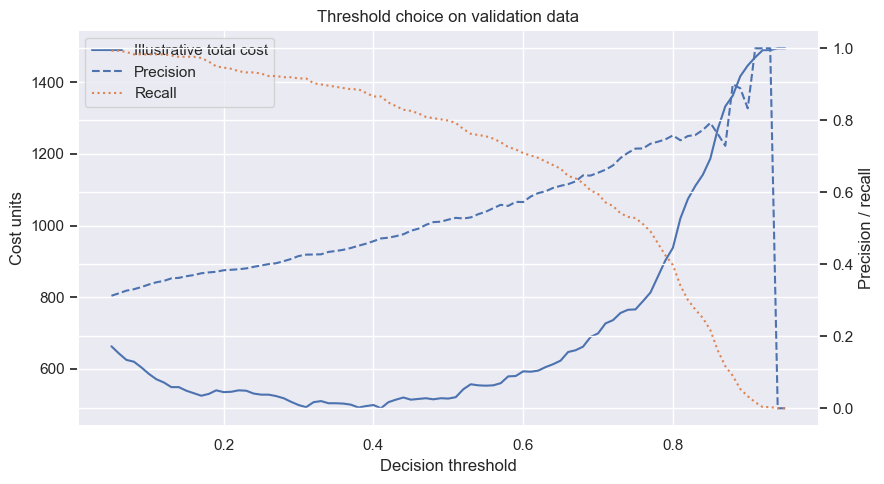

In [14]:
fig, ax1 = plt.subplots(figsize=(9, 5))
ax1.plot(threshold_table["threshold"], threshold_table["cost"], label="Illustrative total cost")
ax1.set_xlabel("Decision threshold")
ax1.set_ylabel("Cost units")
ax1.set_title("Threshold choice on validation data")
ax2 = ax1.twinx()
ax2.plot(threshold_table["threshold"], threshold_table["precision"], linestyle="--", label="Precision")
ax2.plot(threshold_table["threshold"], threshold_table["recall"], linestyle=":", label="Recall")
ax2.set_ylabel("Precision / recall")
lines1, labels1 = ax1.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax1.legend(lines1 + lines2, labels1 + labels2, loc="best")
plt.tight_layout()
plt.show()

#### 5.2 Final evaluation on the held-out test set

At this point, the model family and threshold have been chosen without using the test labels. Now we evaluate once on the test set.

Metrics:
- **Precision:** among customers flagged, what fraction churned?
- **Recall:** among customers who churned, what fraction did we flag?
- **F1:** harmonic mean of precision and recall.
- **Average precision:** summarizes precision-recall ranking quality.
- **ROC-AUC:** probability that a randomly chosen positive is ranked above a randomly chosen negative.
- **Brier score:** mean squared error of predicted probabilities; lower is better, but it reflects both calibration and discrimination.

Accuracy alone can hide poor minority-class performance. Metrics must be read together and compared with operational capacity and business cost.

In [15]:
test_proba = model.predict_proba(X_test)[:, 1]
test_pred = (test_proba >= best_threshold).astype(int)

test_metrics = {
    "model": best_model_name,
    "threshold": best_threshold,
    "accuracy": float(accuracy_score(y_test, test_pred)),
    "precision": float(precision_score(y_test, test_pred, zero_division=0)),
    "recall": float(recall_score(y_test, test_pred, zero_division=0)),
    "f1": float(f1_score(y_test, test_pred, zero_division=0)),
    "average_precision": float(average_precision_score(y_test, test_proba)),
    "roc_auc": float(roc_auc_score(y_test, test_proba)),
    "brier_score": float(brier_score_loss(y_test, test_proba))
}
display(pd.Series(test_metrics, name="held-out test").to_frame())
print(classification_report(y_test, test_pred, target_names=["Stayed", "Churned"], zero_division=0))

,held-out test
model,LogisticRegression
threshold,0.41
accuracy,0.706175
precision,0.47076
recall,0.860963
f1,0.608696
average_precision,0.631672
roc_auc,0.842057
brier_score,0.168006


              precision    recall  f1-score   support

      Stayed       0.93      0.65      0.76      1035
     Churned       0.47      0.86      0.61       374

    accuracy                           0.71      1409
   macro avg       0.70      0.76      0.69      1409
weighted avg       0.81      0.71      0.72      1409



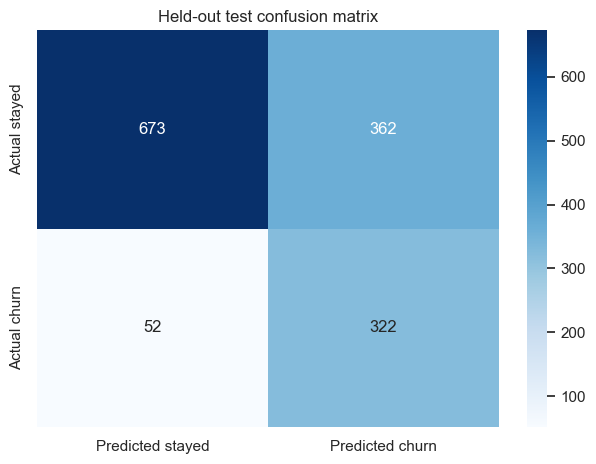

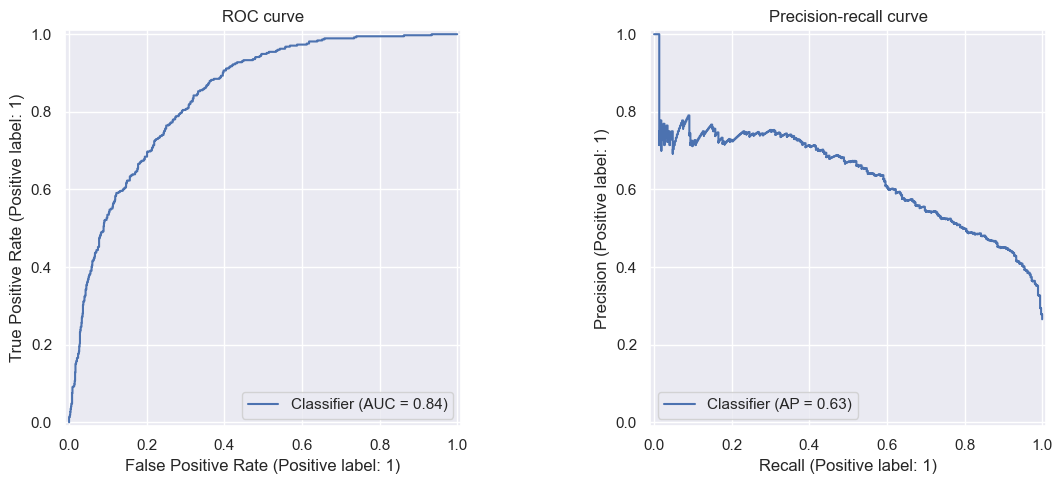

In [16]:
cm = confusion_matrix(y_test, test_pred, labels=[0, 1])
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted stayed", "Predicted churn"],
            yticklabels=["Actual stayed", "Actual churn"])
plt.title("Held-out test confusion matrix")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
RocCurveDisplay.from_predictions(y_test, test_proba, ax=axes[0])
PrecisionRecallDisplay.from_predictions(y_test, test_proba, ax=axes[1])
axes[0].set_title("ROC curve")
axes[1].set_title("Precision-recall curve")
plt.tight_layout()
plt.show()

#### 5.3 Test-set discipline

The test score is an estimate, not a promise about future performance. It can be optimistic if:
- the data was selected in a biased way;
- customers in train and test are not independent;
- the same customers appear more than once;
- the test period is unlike the production period;
- many modeling decisions were made after looking at test results.

If we use test-set findings to change features, thresholds, or models, that test set has become part of development. We should then evaluate the final system on a new untouched test set or use a carefully designed temporal evaluation.

#### 5.4 Error analysis and segment evaluation

Aggregate metrics can conceal failure modes. Inspect false negatives and false positives, and ask whether performance differs across meaningful groups.

This section uses test predictions for a **one-time diagnostic report**. Do not repeatedly tweak the model to maximize these test-segment results. In a real project, define key segments before the final test evaluation, use confidence intervals where possible, and confirm changes on new data.

Segment metrics may be noisy for small groups. Also, attributes such as gender or age require legal, ethical, and business review; do not use them casually to make consequential decisions.

In [17]:
test_diagnostics = X_test.copy()
test_diagnostics["actual_churn"] = np.asarray(y_test)
test_diagnostics["predicted_churn"] = test_pred
test_diagnostics["predicted_probability"] = test_proba
test_diagnostics["error_type"] = np.select(
    [
        (test_diagnostics["actual_churn"] == 1) & (test_diagnostics["predicted_churn"] == 0),
        (test_diagnostics["actual_churn"] == 0) & (test_diagnostics["predicted_churn"] == 1)
    ],
    ["false_negative", "false_positive"],
    default="correct"
)
display(test_diagnostics["error_type"].value_counts().to_frame("count"))
display(test_diagnostics.sort_values("predicted_probability", ascending=False).head(10))

,count
error_type,
correct,995
false_positive,362
false_negative,52


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,...,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,actual_churn,predicted_churn,predicted_probability,error_type
3380,Male,1,Yes,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.10,95.10,1,1,0.933290,correct
6866,Male,0,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,95.45,95.45,1,1,0.922544,correct
3727,Female,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,96.60,291.90,1,1,0.919943,correct
2631,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,99.25,665.45,1,1,0.919249,correct
4585,Female,1,No,No,1,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,85.05,85.05,1,1,0.918142,correct
3346,Female,1,No,No,2,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,84.05,186.05,0,1,0.917706,false_positive
935,Female,1,Yes,No,4,Yes,Yes,Fiber optic,No,No,...,No,Month-to-month,Yes,Electronic check,83.25,308.05,0,1,0.916089,false_positive
6365,Male,1,Yes,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,101.95,700.85,1,1,0.915879,correct
2797,Male,0,No,No,3,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,100.95,329.95,1,1,0.913650,correct
4039,Male,0,No,No,7,Yes,Yes,Fiber optic,No,No,...,Yes,Month-to-month,Yes,Electronic check,94.10,701.30,0,1,0.913219,false_positive


In [18]:
segment_columns = [c for c in ["Contract", "InternetService", "PaymentMethod", "tenure"] if c in X_test.columns]
segment_reports = []

for col in segment_columns:
    if col == "tenure":
        # Use bins only for a descriptive segment report; these bins are not model features.
        groups = pd.cut(X_test[col], bins=[-1, 12, 24, 48, 72], include_lowest=True)
    else:
        groups = X_test[col].astype("string").fillna("<missing>")

    temp = pd.DataFrame({
        "segment": groups.astype(str).to_numpy(),
        "actual": np.asarray(y_test),
        "pred": test_pred,
        "probability": test_proba
    })
    report = temp.groupby("segment").apply(
        lambda g: pd.Series({
            "customers": len(g),
            "actual_churn_rate": g["actual"].mean(),
            "precision": precision_score(g["actual"], g["pred"], zero_division=0),
            "recall": recall_score(g["actual"], g["pred"], zero_division=0),
            "average_probability": g["probability"].mean()
        }),
        include_groups=False
    ).reset_index()
    report.insert(0, "feature", col)
    segment_reports.append(report)

segment_metrics = pd.concat(segment_reports, ignore_index=True) if segment_reports else pd.DataFrame()
display(segment_metrics)

,feature,segment,customers,actual_churn_rate,precision,recall,average_probability
0,Contract,Month-to-month,773.0,0.425614,0.487302,0.933131,0.631775
1,Contract,One year,300.0,0.120000,0.277778,0.416667,0.239611
2,Contract,Two year,336.0,0.026786,0.000000,0.000000,0.069071
3,InternetService,DSL,484.0,0.200413,0.390000,0.804124,0.329781
4,InternetService,Fiber optic,613.0,0.411093,0.514223,0.932540,0.612875
5,InternetService,No,312.0,0.080128,0.333333,0.360000,0.154318
6,PaymentMethod,Bank transfer (automatic),300.0,0.190000,0.477273,0.736842,0.283170
7,PaymentMethod,Credit card (automatic),309.0,0.165049,0.408163,0.784314,0.289275
8,PaymentMethod,Electronic check,474.0,0.434599,0.517241,0.946602,0.630369
9,PaymentMethod,Mailed check,326.0,0.184049,0.371901,0.750000,0.338410


#### 5.5 Feature importance and explanation

Feature importance answers a limited question: **which inputs seem useful to this fitted model under a chosen importance definition?** It does not establish causality.

We use permutation importance on the held-out test set as a diagnostic. It measures how much a chosen metric worsens when one feature is shuffled. With correlated features, importance can be shared or misleading. This output is for interpretation—not a reason to repeatedly optimize on the test set.

For a production explanation requirement, consider global and local explanations, stability, audience needs, and whether the explanation method is appropriate for the model.

,feature,importance_mean,importance_std
4,tenure,0.219258,0.006241
7,InternetService,0.081527,0.019389
17,MonthlyCharges,0.062703,0.017673
14,Contract,0.050785,0.005152
18,TotalCharges,0.024289,0.008699
13,StreamingMovies,0.012795,0.012936
11,TechSupport,0.011848,0.003246
8,OnlineSecurity,0.007234,0.004526
16,PaymentMethod,0.004728,0.006510
10,DeviceProtection,0.003206,0.003070


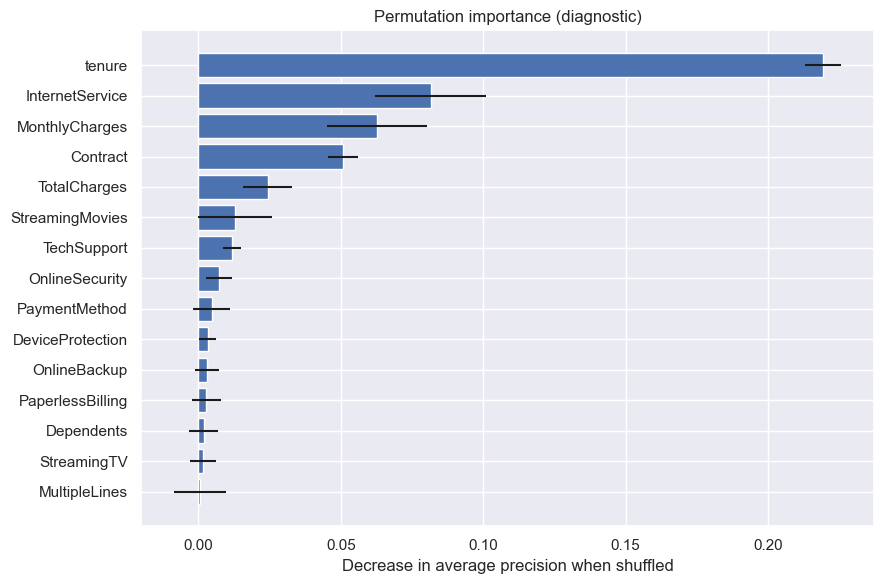

In [19]:
perm = permutation_importance(
    model, X_test, y_test,
    scoring="average_precision",
    n_repeats=5,
    random_state=RANDOM_STATE,
    n_jobs=1
)
importance = pd.DataFrame({
    "feature": X_test.columns,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)
display(importance)

top_imp = importance.head(15).sort_values("importance_mean")
plt.figure(figsize=(9, 6))
plt.barh(top_imp["feature"], top_imp["importance_mean"], xerr=top_imp["importance_std"])
plt.xlabel("Decrease in average precision when shuffled")
plt.title("Permutation importance (diagnostic)")
plt.tight_layout()
plt.show()

#### 5.6 Calibration

A score can rank customers well but still be poorly calibrated. If a group of customers receives predicted risk around 0.30, calibration asks whether approximately 30% of that group actually churns over the defined outcome window.

Calibration matters when probabilities feed expected-value calculations or business decisions. The Brier score is one summary, but a calibration curve is also useful. If you fit a calibration model, do so using cross-validation or a dedicated calibration set—not the final test set.

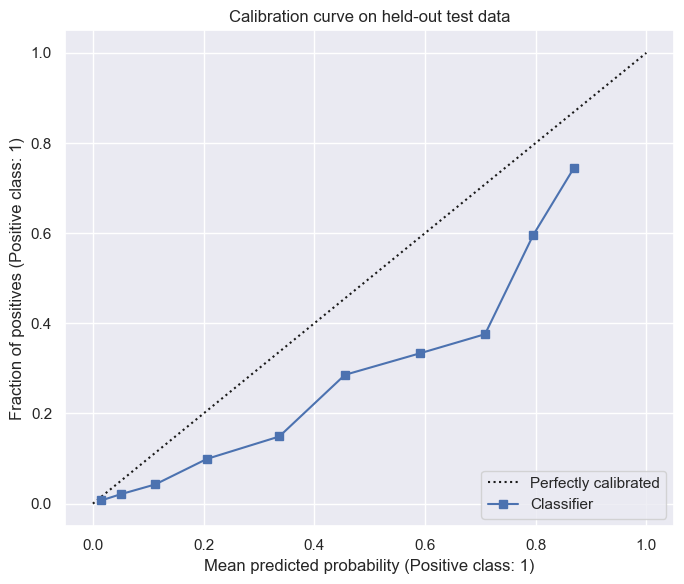

Brier score: 0.168


In [20]:
from sklearn.calibration import CalibrationDisplay

fig, ax = plt.subplots(figsize=(7, 6))
CalibrationDisplay.from_predictions(y_test, test_proba, n_bins=10, strategy="quantile", ax=ax)
ax.set_title("Calibration curve on held-out test data")
plt.tight_layout()
plt.show()
print("Brier score:", round(brier_score_loss(y_test, test_proba), 4))

### STEP 6 — Reproducibility and model management

#### 6.1 Reproducible artifact and model metadata

A model file alone is not enough to reproduce or operate a model. Save:
- the fitted preprocessing + model pipeline;
- feature schema and target definition;
- model family, threshold, and metric snapshot;
- dataset source and run timestamp;
- software versions and random seed.

In a production system, also capture immutable data/model version IDs, code commit, environment/container digest, training parameters, approvals, and lineage. Avoid putting secrets or personal data into metadata.

This notebook writes files under `artifacts/` and `reports/`. Run it from the project root so paths are predictable.

In [21]:
ARTIFACT_DIR = Path("artifacts")
REPORT_DIR = Path("reports")
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)
REPORT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = ARTIFACT_DIR / "churn_pipeline.joblib"
METADATA_PATH = ARTIFACT_DIR / "model_metadata.json"
METRICS_PATH = REPORT_DIR / "test_metrics.json"
CV_PATH = REPORT_DIR / "cross_validation_results.csv"
SEGMENT_PATH = REPORT_DIR / "segment_metrics.csv"

joblib.dump(model, MODEL_PATH)
cv_results.to_csv(CV_PATH, index=False)
segment_metrics.to_csv(SEGMENT_PATH, index=False)

metadata = {
    "project": "customer-churn-prediction",
    "target": TARGET,
    "positive_class": 1,
    "identifier_columns_excluded": ID_COLUMNS,
    "features": list(X_train.columns),
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "selected_model": best_model_name,
    "decision_threshold": best_threshold,
    "threshold_cost_assumptions": {"false_negative_cost": FN_COST, "false_positive_cost": FP_COST},
    "dataset_source": DATA_URL,
    "dataset_rows": int(len(df)),
    "random_state": RANDOM_STATE,
    "python_version": sys.version.split()[0],
    "pandas_version": pd.__version__,
    "scikit_learn_version": sklearn.__version__,
    "created_at_utc": datetime.now(timezone.utc).isoformat(),
    "test_metrics": test_metrics,
    "limitations": [
        "Public educational dataset; not production data",
        "Random split used because a prediction-time chronology is not specified",
        "Threshold costs are illustrative and must be replaced with business estimates"
    ]
}
with open(METADATA_PATH, "w", encoding="utf-8") as f:
    json.dump(metadata, f, indent=2)
with open(METRICS_PATH, "w", encoding="utf-8") as f:
    json.dump(test_metrics, f, indent=2)

print("Saved:")
for path in [MODEL_PATH, METADATA_PATH, METRICS_PATH, CV_PATH, SEGMENT_PATH]:
    print("-", path.resolve(), f"({path.stat().st_size:,} bytes)")

Saved:
- /Users/vivek-18890/Python/learn_python/ml/14-projects/1-telecom-customer-churn/notebook/artifacts/churn_pipeline.joblib (8,490 bytes)
- /Users/vivek-18890/Python/learn_python/ml/14-projects/1-telecom-customer-churn/notebook/artifacts/model_metadata.json (2,086 bytes)
- /Users/vivek-18890/Python/learn_python/ml/14-projects/1-telecom-customer-churn/notebook/reports/test_metrics.json (314 bytes)
- /Users/vivek-18890/Python/learn_python/ml/14-projects/1-telecom-customer-churn/notebook/reports/cross_validation_results.csv (646 bytes)
- /Users/vivek-18890/Python/learn_python/ml/14-projects/1-telecom-customer-churn/notebook/reports/segment_metrics.csv (1,486 bytes)


### STEP 7 — ML-specific testing and quality gates

#### 7.1 Inference contract and prediction smoke test

Training and inference must use the same preprocessing pipeline. Do not separately recreate one-hot encoding, scaling, or imputation in the API; that is a common source of training-serving skew.

The model expects the same feature columns as `X_train`, without `customerID` or `Churn`. Unknown categories are tolerated by the encoder, but schema changes still need deliberate handling.

In [22]:
loaded_model = joblib.load(MODEL_PATH)
expected_features = metadata["features"]

# Construct a valid example from an existing held-out row.
# This demonstrates the interface; it is not a new independent evaluation.
example = X_test.iloc[[0]].copy()
assert list(example.columns) == expected_features

example_probability = float(loaded_model.predict_proba(example)[:, 1][0])
example_prediction = int(example_probability >= metadata["decision_threshold"])
print("Predicted churn probability:", round(example_probability, 4))
print("Predicted class at selected threshold:", example_prediction)

Predicted churn probability: 0.1018
Predicted class at selected threshold: 0


#### 7.2 Model and data tests

Tests catch regressions before deployment. A useful test suite checks:
- required columns and target values;
- no target/identifier leakage into predictors;
- preprocessing can handle missing values and unseen categories;
- model output shape and valid probability range;
- saved artifact can be loaded;
- metric calculations behave as expected.

A notebook assertion is useful while learning, but a production repository should put tests into `tests/` and run them automatically in CI. Do not use test-set performance as a unit-test assertion with a brittle exact value.

In [23]:
# 1) Feature contract: target and identifier are not predictors.
assert TARGET not in X_train.columns
assert "customerID" not in X_train.columns
assert list(X_train.columns) == metadata["features"]

# 2) Inference returns one probability per row, each between 0 and 1.
small_batch = X_test.iloc[:5]
batch_proba = loaded_model.predict_proba(small_batch)[:, 1]
assert batch_proba.shape == (len(small_batch),)
assert np.isfinite(batch_proba).all()
assert ((batch_proba >= 0) & (batch_proba <= 1)).all()

# 3) Unseen categories should not crash OneHotEncoder(handle_unknown="ignore").
unseen = X_test.iloc[[0]].copy()
if categorical_features:
    unseen.loc[unseen.index[0], categorical_features[0]] = "__UNSEEN_CATEGORY__"
unseen_proba = loaded_model.predict_proba(unseen)[:, 1]
assert len(unseen_proba) == 1 and 0 <= unseen_proba[0] <= 1

# 4) A metric sanity check.
assert 0 <= average_precision_score(y_test, test_proba) <= 1
assert 0 <= roc_auc_score(y_test, test_proba) <= 1

print("Notebook smoke tests passed.")

Notebook smoke tests passed.


### Example repository-level tests

A maintainable repository could use `pytest` tests similar to the following. This is a **template**; adapt imports to your actual module names.

```python
def test_probability_is_valid(model, example_features):
    probabilities = model.predict_proba(example_features)[:, 1]
    assert len(probabilities) == len(example_features)
    assert ((probabilities >= 0) & (probabilities <= 1)).all()

def test_unknown_category_is_supported(model, example_features, categorical_column):
    example_features[categorical_column] = "__NEW_CATEGORY__"
    model.predict_proba(example_features)  # must not raise

def test_target_is_not_a_feature(feature_columns):
    assert "Churn" not in feature_columns
    assert "customerID" not in feature_columns
```

Also test malformed API payloads, empty batches, missing columns, extra columns, model-loading failures, and timeout/error behavior.

### STEP 6 — Reproducibility and model management (continued)

#### 6.2 Experiment tracking with MLflow (optional)

Experiment tracking records what changed between runs: data version, code version, parameters, metrics, and artifacts. This makes model comparisons auditable and reproducible.

Install if you want to run this section:

```bash
python -m pip install mlflow
```

For a local learning exercise, MLflow's local file backend is sufficient. Teams often use a centralized tracking server and controlled artifact storage. Do not log secrets or raw sensitive records.

In [24]:
try:
    import mlflow
    import mlflow.sklearn

    mlflow.set_experiment("customer-churn-portfolio")
    with mlflow.start_run(run_name=f"{best_model_name}-selected"):
        mlflow.log_param("selected_model", best_model_name)
        mlflow.log_param("decision_threshold", best_threshold)
        mlflow.log_param("random_state", RANDOM_STATE)
        mlflow.log_param("cv_folds", 5)
        mlflow.log_metrics({
            k: float(v) for k, v in test_metrics.items()
            if isinstance(v, (int, float, np.integer, np.floating))
        })
        mlflow.log_artifact(str(METADATA_PATH))
        mlflow.log_artifact(str(CV_PATH))
        print("Logged run to MLflow.")
except ImportError:
    print("MLflow is not installed. Optional: python -m pip install mlflow")

MLflow is not installed. Optional: python -m pip install mlflow


### STEP 8 — Deployment and serving

#### 8.1 Serving architecture: batch versus online API

Choose serving based on how the prediction is consumed.

- **Batch scoring:** score a customer population on a schedule; efficient for CRM campaigns and daily prioritization.
- **Online API:** score a single customer on demand; useful when a product flow needs a low-latency answer.
- **Streaming:** score events as they arrive; useful when the event and business action require near-real-time processing.

A typical API request path:

`Client → API validation/authentication → feature preparation → model pipeline → response → metrics/logging`

The model should not be retrained inside the request handler. Load a validated artifact at startup, validate requests, handle failures, and keep sensitive values out of logs.

#### 8.2 Minimal FastAPI serving example

Install optional dependencies:

```bash
python -m pip install fastapi uvicorn
```

Save the following as `api.py` next to the `artifacts/` directory, then run `uvicorn api:app --host 0.0.0.0 --port 8000`.

This example is intentionally small. Before real use, add authentication/authorization, request-size limits, rate limiting, robust schema validation, timeouts, structured logs, model-version reporting, and deployment health checks.

In [25]:
fastapi_source = r'''
from pathlib import Path
import json
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict

BASE_DIR = Path(__file__).resolve().parent
model = joblib.load(BASE_DIR / "artifacts" / "churn_pipeline.joblib")
metadata = json.loads((BASE_DIR / "artifacts" / "model_metadata.json").read_text())
features = metadata["features"]
threshold = float(metadata["decision_threshold"])

app = FastAPI(title="Customer Churn Prediction API", version="1.0.0")

class PredictionRequest(BaseModel):
    model_config = ConfigDict(extra="forbid")
    features: dict

@app.get("/health/live")
def liveness():
    return {"status": "alive"}

@app.get("/health/ready")
def readiness():
    return {"status": "ready", "model": metadata["selected_model"]}

@app.post("/predict")
def predict(request: PredictionRequest):
    missing = sorted(set(features) - set(request.features))
    extra = sorted(set(request.features) - set(features))
    if missing or extra:
        raise HTTPException(
            status_code=422,
            detail={"missing_features": missing, "unexpected_features": extra}
        )
    try:
        frame = pd.DataFrame([{name: request.features[name] for name in features}])
        probability = float(model.predict_proba(frame)[:, 1][0])
        return {
            "churn_probability": probability,
            "predicted_churn": int(probability >= threshold),
            "threshold": threshold,
            "model_version": metadata.get("created_at_utc")
        }
    except Exception as exc:
        # In production, log a sanitized error with a request/correlation ID.
        raise HTTPException(status_code=400, detail="Invalid prediction input") from exc
'''
print(fastapi_source)


from pathlib import Path
import json
import joblib
import pandas as pd
from fastapi import FastAPI, HTTPException
from pydantic import BaseModel, ConfigDict

BASE_DIR = Path(__file__).resolve().parent
model = joblib.load(BASE_DIR / "artifacts" / "churn_pipeline.joblib")
metadata = json.loads((BASE_DIR / "artifacts" / "model_metadata.json").read_text())
features = metadata["features"]
threshold = float(metadata["decision_threshold"])

app = FastAPI(title="Customer Churn Prediction API", version="1.0.0")

class PredictionRequest(BaseModel):
    model_config = ConfigDict(extra="forbid")
    features: dict

@app.get("/health/live")
def liveness():
    return {"status": "alive"}

@app.get("/health/ready")
def readiness():
    return {"status": "ready", "model": metadata["selected_model"]}

@app.post("/predict")
def predict(request: PredictionRequest):
    missing = sorted(set(features) - set(request.features))
    extra = sorted(set(request.features) - set(features))
    if missing or extr

#### 8.3 API smoke-test workflow

1. Start the API locally.
2. Open `/docs` and inspect the generated schema.
3. Send a valid payload containing every feature from `metadata["features"]`.
4. Verify malformed and extra-feature requests return a client error.
5. Verify health endpoints work even when no prediction is requested.
6. Add automated integration tests that start the app and call the endpoints.
7. Measure p50/p95/p99 latency under realistic concurrency—not only a single local request.

The generated code above prints the source so you can copy it to `api.py`. It is not automatically written to disk.

#### 8.4 Docker and CI/CD

Containerization helps package code and dependencies consistently. It does not by itself guarantee reproducibility: the base image, dependency versions, model artifact, and runtime configuration must also be controlled.

A typical workflow:
1. lint and run unit tests;
2. validate data contracts;
3. train/evaluate in a controlled job;
4. enforce quality gates;
5. package a versioned artifact and container;
6. deploy to staging;
7. smoke/load test;
8. canary or shadow release;
9. promote or roll back based on observed behavior.

Do not automatically promote a model merely because the training job completed.

In [26]:
dockerfile_example = r'''
FROM python:3.12-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY api.py .
COPY artifacts/ artifacts/
EXPOSE 8000
USER 10001
CMD ["uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]
'''
requirements_example = '''
pandas
numpy
scikit-learn
joblib
fastapi
uvicorn
pydantic
'''
print("----- Dockerfile -----")
print(dockerfile_example)
print("----- requirements.txt (example) -----")
print(requirements_example)

----- Dockerfile -----

FROM python:3.12-slim
WORKDIR /app
ENV PYTHONDONTWRITEBYTECODE=1 PYTHONUNBUFFERED=1
COPY requirements.txt .
RUN pip install --no-cache-dir -r requirements.txt
COPY api.py .
COPY artifacts/ artifacts/
EXPOSE 8000
USER 10001
CMD ["uvicorn", "api:app", "--host", "0.0.0.0", "--port", "8000"]

----- requirements.txt (example) -----

pandas
numpy
scikit-learn
joblib
fastapi
uvicorn
pydantic



Example commands (after saving `api.py`, `Dockerfile`, and `requirements.txt`):

```bash
docker build -t churn-api:local .
docker run --rm -p 8000:8000 churn-api:local
```

Production hardening:
- pin dependency versions and use a lockfile;
- scan dependencies and container images for vulnerabilities;
- run as a non-root user;
- do not bake secrets into the image;
- use a small, maintained base image;
- define CPU/memory requests and limits in the deployment platform;
- keep model artifacts immutable and identify their versions;
- ensure rollback can restore the previous artifact and application version.

### STEP 9 — Production monitoring

#### 9.1 Service health, data drift, and model quality

These are different concepts:

- **Service monitoring:** request rate, error rate, latency, CPU/memory, saturation, timeouts.
- **Data-quality monitoring:** missingness, invalid ranges, unexpected categories, schema changes.
- **Data drift:** input feature distributions change over time.
- **Concept drift:** the relationship between inputs and churn changes.
- **Model-quality monitoring:** precision/recall/calibration after actual outcomes become available.

Drift does not automatically mean model performance has degraded. A drift alert is a signal to investigate, not a reason to retrain blindly.

In churn, labels may arrive weeks or months after scoring. Store the prediction timestamp, model version, features or a privacy-safe reference, score, action, and later outcome so that predictions can be evaluated when labels mature. Define retention and access controls for these records.

In [27]:
def population_stability_index(reference, current, bins=10, eps=1e-6):
    """Simple PSI for a numeric feature. PSI is a drift signal, not a quality metric."""
    ref = pd.Series(reference).dropna().astype(float)
    cur = pd.Series(current).dropna().astype(float)
    if ref.empty or cur.empty:
        raise ValueError("Both reference and current distributions must contain values.")

    # Quantile bins from reference population; deduplicate edges for constant/tied values.
    edges = np.unique(np.quantile(ref, np.linspace(0, 1, bins + 1)))
    if len(edges) < 3:
        return 0.0  # no meaningful bins for a near-constant reference feature
    edges[0], edges[-1] = -np.inf, np.inf

    ref_counts = pd.cut(ref, bins=edges, include_lowest=True).value_counts(sort=False)
    cur_counts = pd.cut(cur, bins=edges, include_lowest=True).value_counts(sort=False)
    ref_pct = np.clip(ref_counts.to_numpy() / max(ref_counts.sum(), 1), eps, None)
    cur_pct = np.clip(cur_counts.to_numpy() / max(cur_counts.sum(), 1), eps, None)
    return float(np.sum((cur_pct - ref_pct) * np.log(cur_pct / ref_pct)))

# Demonstration only: split one feature into two samples to illustrate the calculation.
reference_tenure = X_train["tenure"]
current_tenure_example = X_test["tenure"]
psi_example = population_stability_index(reference_tenure, current_tenure_example)
print("Example PSI for tenure (train vs test sample):", round(psi_example, 4))
print("This is not a production drift alert: train/test are from the same source and period.")

Example PSI for tenure (train vs test sample): 0.0078
This is not a production drift alert: train/test are from the same source and period.


#### 9.2 Delayed-label evaluation pattern

A production evaluation table should connect each prediction to the actual outcome only after the label window has matured. Then calculate metrics by scoring date, model version, channel, and key segments.

Pseudo-workflow:
1. Persist `customer_key`, `scored_at`, `model_version`, `score`, `decision`, and an approved feature snapshot/reference.
2. Define the outcome window (for example, churn within the next 30 days).
3. Wait until that window has matured before treating a missing outcome as a negative.
4. Join matured outcomes to predictions.
5. Calculate ranking, threshold, calibration, and business metrics.
6. Compare with a baseline and previous model; alert on meaningful degradation.
7. Investigate before retraining or rolling back.

Do not count not-yet-matured labels as “did not churn”; that creates biased monitoring.

### STEP 10 — Operations and continuous improvement

#### 10.1 Retraining, release gates, rollback, and incident response

A robust ML system needs an operational policy—not just a cron job that retrains every week.

### Example release gates (illustrative, not universal)
- data schema and data-quality checks pass;
- no known leakage or prohibited feature;
- validation average precision exceeds a defined baseline;
- recall at the capacity-limited threshold meets the business requirement;
- probability calibration is acceptable if probabilities drive value calculations;
- segment checks show no unexplained severe regressions;
- latency, memory, and error-rate targets pass;
- artifact is reproducible and approved.

### Retraining triggers
- enough new, mature labels are available;
- confirmed model-quality degradation;
- meaningful changes in the business or population;
- a scheduled review finds the model stale.

### Rollback and incident response
- keep the previous known-good model and application image;
- make model version explicit in responses and logs;
- define who owns an alert and how quickly it should be acknowledged;
- document how to disable automated actions safely;
- record the incident, root cause, and follow-up actions.

Retraining should be gated by evaluation and approval. A new model is not necessarily a better model.

### STEP 11 — Performance, cost, and security

#### 11.1 Performance, cost, privacy, security, and responsible ML

Before production, measure rather than guess:
- throughput and p50/p95/p99 prediction latency;
- model loading time and memory footprint;
- batch size effects;
- cost per 1,000 or 1,000,000 predictions;
- CPU/memory under concurrency;
- failure behavior under dependency or network problems.

Security and privacy checklist:
- collect only features needed for the use case;
- document lawful purpose, access, retention, and deletion;
- avoid logging raw customer attributes or full requests;
- authenticate and authorize prediction callers;
- validate input types, lengths, ranges, and payload size;
- manage secrets outside source code and container images;
- pin and scan dependencies;
- protect artifacts and tracking stores;
- audit access to model outputs and customer records.

Responsible ML:
- examine performance and error rates across relevant groups where legally and ethically appropriate;
- investigate whether features are proxies for protected or sensitive attributes;
- avoid treating predictive association as a causal explanation;
- use human review and controlled experiments for consequential interventions;
- document limitations, intended use, and prohibited use.

#### 11.2 Business validation: does a better model create value?

Offline metrics are necessary but not sufficient. A retention team can contact only a limited number of customers, and contacting a customer may or may not change their decision.

A simplified expected-value framing is:

`Expected value = expected incremental retained value − outreach/offer cost − operational cost`

But **incremental** retention requires knowing what would have happened without the intervention. A churn model estimates risk; it does not necessarily estimate who can be persuaded to stay. An uplift model or randomized experiment can help estimate treatment effect.

A practical pilot:
1. define eligible customers and intervention;
2. randomly assign treatment and control where appropriate;
3. track offer cost, retention, complaints, and long-term value;
4. estimate incremental effect and uncertainty;
5. roll out only if the benefit outweighs cost and risks.

### STEP 12 — Documentation and interview readiness

#### 12.1 Production architecture summary

A reasonable first version for this portfolio project:

- **Training:** Python + pandas + scikit-learn pipeline.
- **Experiment tracking:** optional MLflow.
- **Artifact:** versioned serialized pipeline plus metadata.
- **Serving:** FastAPI for online predictions or a scheduled batch job.
- **Packaging:** Docker.
- **Quality:** pytest + CI checks.
- **Monitoring:** API/service metrics, data-quality checks, drift signals, and delayed-label evaluation.
- **Operations:** documented gates, promotion, rollback, and incident ownership.

Avoid adding Kubernetes, a feature store, Kafka, or a complex orchestration platform just to make the diagram look impressive. Add infrastructure when the use case, scale, reliability requirements, or team environment justify it.

#### 12.2 Interview questions — practice explaining the *why*

### Business and data
1. What is the business problem and who acts on the prediction?
2. Why is churn prediction not the same as predicting who will respond to a retention offer?
3. What does the target mean, and when is it observable?
4. How would you detect target leakage?
5. Why might a random split be misleading for churn?
6. How would you version data and document lineage?

### Modeling and evaluation
7. Why use a pipeline?
8. Why stratified cross-validation?
9. Why average precision rather than accuracy?
10. Explain precision, recall, F1, ROC-AUC, PR curve, and Brier score.
11. Why is 0.5 not always the best threshold?
12. Why select the threshold on validation data rather than test data?
13. What is the difference between ranking quality and calibration?
14. What do class weights do, and what do they not do?
15. How would you handle a model that has strong overall metrics but poor recall for a key segment?
16. How would you know whether an apparent improvement is statistically meaningful?

### Engineering and production
17. How do you prevent training-serving skew?
18. What should be included in model metadata?
19. What would you test in CI?
20. What is the difference between data drift and concept drift?
21. Why can drift happen without model-quality degradation?
22. How do you monitor a model when labels arrive late?
23. When would you choose batch scoring over an API?
24. What would you log, and what should not be logged?
25. How would you roll back a bad model?
26. How would you measure p95 latency and throughput?
27. Why should retraining not automatically imply promotion?
28. How would you prove this project creates business value?

### Your 2-minute project explanation — fill in after running
- **Problem:** ...
- **Data and target:** ...
- **Leakage/data-quality checks:** ...
- **Baseline:** ...
- **Models compared and why:** ...
- **Validation strategy:** ...
- **Chosen model and actual test metrics:** ...
- **Threshold and business assumption:** ...
- **Error analysis insight:** ...
- **Serving/monitoring plan:** ...
- **Limitations and next improvement:** ...

Never claim a metric, production deployment, or business impact you did not actually measure.

#### 12.3 Final checklist — implementation versus design guidance

Use this checklist honestly. A topic being described in Markdown does not mean a complete production implementation exists.

### Implemented in this notebook
- [ ] Business objective and metric rationale reviewed
- [ ] Public data loaded and schema/quality checks run
- [ ] EDA and target imbalance examined
- [ ] Leakage-aware feature/target separation and train/validation/test split
- [ ] Preprocessing embedded in sklearn pipelines
- [ ] Baseline and cross-validated model comparison
- [ ] Validation-based threshold choice with explicitly illustrative costs
- [ ] Held-out test evaluation and error/segment analysis
- [ ] Permutation importance and calibration diagnostic
- [ ] Model artifact, metadata, metrics, and comparison reports saved
- [ ] Smoke tests for prediction shape, valid probabilities, and unseen categories
- [ ] Optional MLflow logging attempted if installed
- [ ] Drift calculation demonstrated with a warning that it is not production monitoring

### Demonstrated as code templates / operational design (not fully deployed here)
- [ ] FastAPI source is printed for you to save as `api.py`
- [ ] Dockerfile and dependency examples are printed, not automatically deployed
- [ ] CI/CD, registry/promotion, canary, rollback, incident response are design guidance
- [ ] Production authentication, authorization, alerting, load testing, and secure infrastructure are not provided by this notebook alone
- [ ] Delayed-label monitoring needs a real prediction/outcome store and matured labels
- [ ] Business impact needs a controlled intervention experiment

### Before you call the project complete
1. Run every cell from a fresh kernel.
2. Confirm all outputs and saved files.
3. Review warnings rather than suppressing them blindly.
4. Save the exact library versions and actual metrics from your run.
5. Move reusable logic into modules and add `pytest` tests.
6. Run CI, test the API, build the container, and perform a load test.
7. Update the README with real results and honest limitations.
8. Practice answering the questions above without reading the notebook.

**Completion standard:** the goal is not to have the most tools. It is to understand each choice, know its trade-offs, validate the model honestly, and show a reproducible path from data to an operational decision.